# Hälsostudie – Statistisk analys i Python

Del 2: Explorativ dataanalys och statistiska metoder

Denna rapport presenterar en explorativ dataanalys av ett simulerat hälsodatamaterial. Analysen omfattar beskrivande statistik, visualiseringar och statistiska metoder för att undersöka samband och skillnader i datasetet.

Arbetet genomförs inom ramen för kursen PYSTDA45 på Data Science-utbildningen.

In [3]:
%load_ext autoreload 
%autoreload 2
import sys
import pandas as pd
sys.path.insert(0, '..')
from src.health_analyzer import HealthAnalyzer
pd.set_option('display.width', 200)
pd.set_option('display.max_rows', 25)

# Please try alternative palettes: 'glasbey_20' or 'okabe_ito_tritanopi' for diagrams by changing argument here
analyzer = HealthAnalyzer(palette = 'okabe_ito')

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


- Jag har satt index till id, och lagt till bmi som kolumn för bättre värde av kroppsbyggnad än längd och vikt för sig.
- Ändrat sex and smoker till binära kategorier för bättre korrelationsprövningar i del 2.

#### Rimlighetskontroll av hälsovärden
För att identifiera potentiellt orimliga värden har jag jämfört datasetets observationer med medicinsk information och rekommenderade gränsvärden från 1177 Vårdguiden.  
Gränsvärdena används som stöd vid bedömningen av avvikande observationer. Det är viktigt att skilja mellan medicinskt avvikande värden och faktiskt orimliga mätvärden, eftersom extrema hälsovärden kan förekomma i verkligheten.  
Information om medicinska gränsvärden och hälsorelaterade mått har hämtats från [1177 Vårdguiden](https://www.1177.se/).  

- 12  < BMI eller > 50
- 50  < Systoliskt blodtryck (mmHg) eller > 250
- 1.0 < Kolesterol (mmol/L) eller > 10.0

Gränserna är avsedda att fånga potentiellt orimliga mätvärden, inte medicinskt avvikande värden och är mina egna valda gränser för just rimlighetskontroll.

#### Spridning

In [4]:
analyzer.summary_statistics()

,Medelvärde,Median,Min,Max
Ålder,49.43,50.00,18.0,90.00
Vikt (kg),73.41,73.20,33.7,114.40
Längd (cm),171.85,171.35,144.4,200.40
Systoliskt blodtryck (mmHg),149.18,149.40,106.8,185.90
Kolesterol (mmol/L),4.93,4.97,2.5,7.88


Medelvärden och median ligger väldigt nära varandra för de undersökta variablerna, vilket indikerar relativt symmetriska fördelningar.  
Spridningen ser ut att vara ganska stor i alla variabler.


# Korrelationer
Korrelationsanalysen har genomförts med Pandas `DataFrame.corr()`, som stöder Pearson, Spearman och Kendall.
([Pandas documentation](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html)).  
Samtliga tre metoder har testats för att jämföra hur valet av korrelationsmetod påverkar resultaten. Pearson valdes som huvudsaklig metod för den fortsatta analysen.

In [5]:
print('Korrelation pearson:\n',analyzer.correlation_matrix('pearson'))
print('\nKorrelation spearman:\n', analyzer.correlation_matrix('spearman'))
print('\nKorrelation kendall:\n', analyzer.correlation_matrix('kendall'))

Korrelation pearson:
                Ålder       Kön     Längd      Vikt  Blodtryck  Kolesterol    Rökare   Sjukdom       BMI
Ålder       1.000000 -0.030746 -0.004653 -0.017309   0.607578    0.491173  0.041412  0.021629 -0.011153
Kön        -0.030746  1.000000  0.693659  0.457721   0.082633    0.046610 -0.049217  0.060347  0.033244
Längd      -0.004653  0.693659  1.000000  0.320260   0.086297   -0.043344 -0.048950  0.033194 -0.295205
Vikt       -0.017309  0.457721  0.320260  1.000000   0.179467    0.256214  0.020540  0.037424  0.803614
Blodtryck   0.607578  0.082633  0.086297  0.179467   1.000000    0.368441  0.016314  0.031059  0.128814
Kolesterol  0.491173  0.046610 -0.043344  0.256214   0.368441    1.000000  0.011511  0.013729  0.292370
Rökare      0.041412 -0.049217 -0.048950  0.020540   0.016314    0.011511  1.000000  0.078006  0.046613
Sjukdom     0.021629  0.060347  0.033194  0.037424   0.031059    0.013729  0.078006  1.000000  0.018864
BMI        -0.011153  0.033244 -0.295205  

En jämförelse mellan Pearson och Spearman visar mycket likartade korrelationsvärden för de undersökta variablerna. Detta tyder på att de identifierade sambanden inte är särskilt känsliga för valet mellan metoderna.
Kendall ger för de kontinuerliga variablerna genomgående lägre koefficienter, vilket beror på att metoden använder en annan beräkningsgrund och skala. De övergripande slutsatserna om sambandens riktning kvarstår dock.   
För par av binära variabler (kön, rökare och sjukdom) är värdena identiska i alla tre metoderna.


 **Ålder, blodtryck och kolesterol** 

- Ålder korrelerar med både blodtryck (r = 0,61) och kolesterol (r = 0,49), vilket är ett förväntat resultat.
- Kolesterol och blodtryck korrelerar måttligt (r = 0,37), vilket är förväntat. Eftersom båda hänger ihop med ålder är det troligt att en stor del av sambandet beror på ålder.  

**Sjukdom**  
- Korrelationerna mellan sjukdom och de kontinuerliga variablerna ligger nära noll.
- Rökare har den starkaste korrelationen med sjukdom (r = 0,08). Den är liten men stämmer med att sjukdom är vanligare bland rökare. Övriga variabler ligger under gränsen från vad som kan skiljas från 0 (r < 0,04).  
- Rökare har ingen märkbar korrelation med blodtryck (r = 0,02).

**Kön**  
- Kön korrelerar med längd (r = 0,69) och vikt (r = 0,46), vilket visar att män i genomsnitt är längre och tyngre.
- Korrelationen mellan kön och blodtryck är svag (r = 0,08). Korrelationerna med kolesterol, rökare (r = −0,05) och sjukdom (r = 0,06) är mycket svaga och kan inte skiljas från noll. Sambandet med rökare går i samma riktning som den högre andelen rökande kvinnor (28,8 % mot 24,4 %), men är inte tydligt i detta stickprov.   

**BMI**  
- BMI har en svag till måttlig korrelation med kolesterol (r ≈ 0,29) och en svag korrelation med blodtryck (r ≈ 0,13).

#### Val av färgpalett
I rapportens diagram används färgpaletten Okabe-Ito. Den valdes eftersom den är utformad för att färgerna ska vara lättare att särskilja för personer med olika former av färgseendedefekter.  
Detta bidrar till ökad tillgänglighet och gör diagrammen lättare att tolka för en bredare läsarkrets.   
Det blir särskilt relevant eftersom rapporten behandlar medicinska data.  
https://jfly.uni-koeln.de/color/ (Okabe & Ito, 2008).    
Jag har valt att ändra färgernas ursprungliga ordning för att skapa större variation mellan ljusa och mörka toner i diagrammen samt variation mellan gråtoner i svartvita format. Gult och svart har jag placerat sist i paletten för att få en mer konsekvent visuell balans.  
Läs mer om min policy här: [Data Visualization Policy](../visualization_policy.md).  

# Demografisk beskrivning

In [6]:
print('Andel sjukdom vs ingen sjukdom (%):')
display(analyzer.disease_share())
print('Åldersfördelning mellan könen:')
display(analyzer.age_by_sex())

Andel sjukdom vs ingen sjukdom (%):


,Andel (%)
Sjukdomsstatus,
Ingen sjukdom,94.12
Sjukdom,5.88


Åldersfördelning mellan könen:


,Medelvärde,Median,Standardavvikelse,Antal
Kön,,,,
Kvinna,49.9,50.0,14.5,403
Man,49.0,49.0,14.5,397


#### Histogram/KDE över ålder
- Visar populationens sammansättning och skillnader mellan män och kvinnors åldersfördelning i populationen.

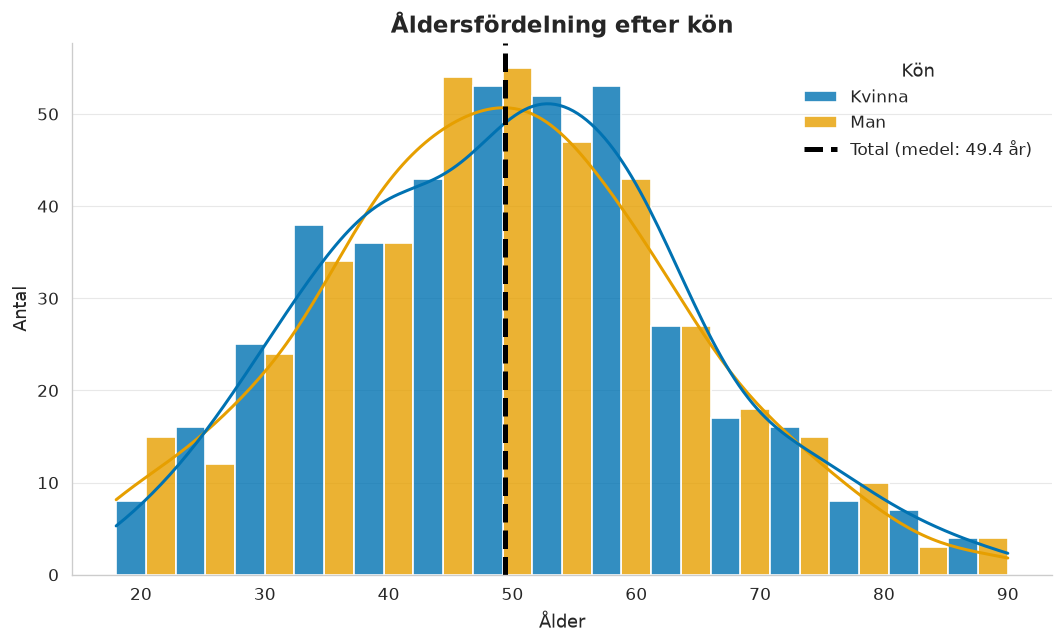

In [34]:
analyzer.plot_dodged_distribution();

Åldersfördelningen är relativt lika mellan män och kvinnor och uppvisar en ungefärlig normalfördelning.  
Diagrammet ger inga tydliga indikationer på större skillnader mellan könen.

# Hälsotillstånd

#### Histogram/KDE över blodtryck	
- Fördelningen av blodtryck	Identifierar spridning och extremvärden

In [ ]:
dis_plot_sys = sns.displot(data=df, x='systolic_bp', kde=True, bins=15, color=viz.okabe_ito[0], alpha=0.8)
# TODO ska byta till histplot med kde istället för displot till del2. Ger samma resultat men: 
# sns.displot() ger en fig istället för ax och bör helst användas till facetterade diagram
plt.title('Fördelning av systoliskt blodtryck')
plt.xlabel('Systoliskt blodtryck (mmHg)')
plt.ylabel('Antal')
plt.tight_layout()
plt.show()

Fördelningen ser ungefär symmetrisk ut.

### Stapeldiagram för antal rökare fördelat på kön
(med kompletterande tabell för andel)

In [ ]:
sns.countplot(x='smoker',data=df, palette=viz.okabe_ito[:2], hue='sex', saturation=1, edgecolor=viz.okabe_ito[7])
plt.title('Antal rökare fördelat på kön')
plt.xlabel('Rökare')
plt.ylabel('Antal')
ax = plt.gca()
ax.legend_.set_title('Kön')
ax.legend_.texts[0].set_text('Kvinna')
ax.legend_.texts[1].set_text('Man')
plt.tight_layout()
plt.show()

smoker_share = pd.crosstab(
    df['sex'],
    df['smoker'],
    normalize='index') * 100
print('Andel rökare i (%) fördelat på kön:\n', smoker_share.round(1))

Visar på en liten överrepresentation av kvinnor som röker i datasetet.

#### Linjär regression
Visualiseras med Seaborns funktion lmplot(). Regressionslinjen skattades med linjär regression och ett 95-procentigt konfidensintervall beräknades med bootstrap.

Bootstrap valdes eftersom metoden ger en empirisk uppskattning av osäkerheten i regressionslinjen utan att enbart förlita sig på analytiska fördelningsantaganden. Konfidensintervallet beräknades med 5 000 bootstrap-omtagningar för att öka stabiliteten i skattningen.  
Seaborn. (u.å.). seaborn.lmplot. Seaborn documentation. https://seaborn.pydata.org/generated/seaborn.lmplot.html

## Kolesterol – blodtryck	
- Finns det ett samband mellan högt kolesterol och högt blodtryck?  
Värt att undersöka vidare då korrelationstabellen visade på en svag till måttlig korrelation.  

In [ ]:
lmplot = sns.lmplot(data=df, x='cholesterol', y='systolic_bp', hue='sex', palette=viz.okabe_ito[:2],
    markers=['o', 'h'], scatter_kws={'alpha': 0.6}, height=6, aspect=1.5, ci=95, n_boot=5000, seed=42)

plt.title('Kolesterol i förhållande till systoliskt blodtryck')
plt.xlabel('Kolesterol (mmol/L)')
plt.ylabel('Systoliskt blodtryck (mmHg)')
lmplot.legend.set_title('Kön')
lmplot.legend.texts[0].set_text('Kvinna')
lmplot.legend.texts[1].set_text('Man')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print(f'Korrelation mellan kolesterol och systoliskt blodtryck uppdelat efter kön:\n{df.groupby('sex')[['cholesterol', 'systolic_bp']].corr().iloc[[1, 3],0].to_string()}')

Resultatet visar en svag till måttlig positiv korrelation mellan kolesterol och systoliskt blodtryck i hela datasetet (Pearsons r = 0.368).   
Sambandet verkar vara något starkare för kvinnor (r = 0.412) än för män (r = 0.317).  

Konfidensintervallen för regressionslinjerna överlappar, vilket tyder på att det inte finns någon tydlig skillnad mellan gruppernas skattade samband.   
Diagrammet ger dock inte tillräckligt underlag för att avgöra om skillnaden är statistiskt signifikant.  

Det kan vara intressant att undersöka om skillnaden kvarstår efter kontroll för exempelvis ålder, eller om den kan förklaras av skillnader i andra faktorer, såsom rökvanor då vi tidigare visat att det finns en liten överrepresentation av rökning hos kvinnor i datasetet.

#### Låddiagram och kvartilberäkning
Låddiagram (boxplots) används för att jämföra fördelningen av olika variabler mellan grupper med och utan sjukdom.   
Diagrammen visar medianen och interkvartilavståndet (IQR), som omfattar de mittersta 50 procenten av observationerna. Whiskers sträcker sig till den yttersta observationen inom 1,5 gånger IQR från respektive kvartil. Observationer utanför dessa gränser markeras som potentiellt avvikande värden.  
Metoden valdes eftersom median och IQR ger en robust beskrivning av centralvärde och spridning, även vid snedfördelade data.  

Låddiagrammen kompletterades med svärmdiagram för att ge en tydligare bild av gruppernas olika storlekar och och ge en mer detaljerad bild av spridningen.

Referenser:  
Seaborn. (u.å.). seaborn.boxplot. Seaborn documentation. https://seaborn.pydata.org/generated/seaborn.boxplot.html  
Seaborn. (u.å.). seaborn.swarmplot. Seaborn documentation. https://seaborn.pydata.org/generated/seaborn.swarmplot.html  

# Undersökning av sjukdomsrisk
#### A. Blodtryck uppdelat efter sjukdom

In [ ]:
disease_counts = df['disease'].value_counts()
labels = {0: f'Ingen sjukdom (antal: {disease_counts.get(0, 0)})',
        1: f'Sjukdom (antal: {disease_counts.get(1, 0)})'}

fig, ax = plt.subplots(figsize=(9, 6))
sns.boxplot(data=df, x='disease',y='systolic_bp',hue='disease',palette=viz.okabe_ito[:2],legend=False, ax=ax, width=0.6, saturation=1)
sns.swarmplot(data=df,x='disease',y='systolic_bp',color=viz.okabe_ito[7],alpha=0.3,size=4,ax=ax)
plt.title('Systoliskt blodtrycksfördelning efter sjukdomsstatus')
plt.xlabel('Sjukdomsstatus')
plt.ylabel('Systoliskt blodtryck (mmHg)')
plt.xticks([0, 1], [labels[0], labels[1]])
plt.tight_layout()
plt.show()

Fördelningen av systoliskt blodtryck uppvisar inga tydliga skillnader mellan grupperna med respektive utan sjukdom.   
Medianvärden och spridning verkar vara relativt lika.  
 Den mindre gruppens värden ryms till stor del inom variationsintervallet för den större gruppen i detta dataset och finns därför inget tydligt visuellt stöd för ett samband mellan systoliskt blodtryck och sjukdomsstatus.

#### B. Kolesterol uppdelat efter sjukdom

In [ ]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.boxplot(data=df, x='disease',y='cholesterol',hue='disease',palette=viz.okabe_ito[:2],legend=False, ax=ax, width=0.6, saturation=1)
sns.swarmplot(data=df,x='disease',y='cholesterol',color=viz.okabe_ito[7],alpha=0.3,size=4,ax=ax)
plt.title('Fördelning av kolesterol efter sjukdomsstatus')
plt.xlabel('Sjukdomsstatus')
plt.ylabel('Kolesterol (mmol/L)')
plt.xticks([0, 1], [labels[0], labels[1]])
plt.tight_layout()
plt.show()

Fördelningen av kolesterol uppvisar inga tydliga skillnader mellan grupperna med respektive utan sjukdom.   
Medianvärden och spridning verkar vara relativt lika.  
Den mindre gruppens värden ryms till stor del inom variationsintervallet för den större gruppen i detta dataset och finns därför inget tydligt visuellt stöd för ett samband mellan kolesterol och sjukdomsstatus.

#### C. Ålder uppdelat efter sjukdomsstatus

In [ ]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.boxplot(data=df, x='disease',y='age',hue='disease',palette=viz.okabe_ito[:2],legend=False, ax=ax, width=0.6,saturation=1)

sns.swarmplot(data=df,x='disease',y='age',color=viz.okabe_ito[7],alpha=0.3,size=4,ax=ax)
plt.xticks([0, 1], [labels[0], labels[1]])

plt.title('Åldersfördelning efter sjukdomsstatus')
plt.xlabel('Sjukdomsstatus')
plt.ylabel('Ålder (år)')
plt.tight_layout()
plt.show()

Åldersfördelningen uppvisar inga tydliga skillnader mellan grupperna med respektive utan sjukdom.   
Medianvärden och spridning verkar vara relativt lika.  
Den mindre gruppens värden ryms till stor del inom variationsintervallet för den större gruppen i detta dataset och finns därför inget tydligt visuellt stöd för ett samband mellan ålder och sjukdomsstatus.

#### D. Sjukdomsförekomst bland rökare och icke-rökare

In [ ]:
smoker_proportion = pd.crosstab(df['disease'],df['smoker'], normalize='index').reindex(columns=['No', 'Yes']) * 100
disease_counts = df['disease'].value_counts()

labels = [f'Ingen sjukdom (n={disease_counts.get(0, 0)})',f'Sjukdom (n={disease_counts.get(1, 0)})']
smoker_proportion.index = labels

ax = smoker_proportion.plot(edgecolor=viz.okabe_ito[7], kind='bar', stacked=True, color=[viz.okabe_ito[0], viz.okabe_ito[1]], figsize=(9, 6), alpha = 1)

ax.set_title('Rökstatus efter sjukdomsförekomst')
ax.set_xlabel('Sjukdomsstatus')
ax.set_ylabel('Andel deltagare (%)')
ax.set_ylim(0, 110)
ax.legend(['Icke-rökare', 'Rökare'],title='Rökstatus')
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

smoker_risk = pd.crosstab(
    df['smoker'],
    df['disease'],
    normalize='index'
) * 100
smoker_risk.columns = ['Ingen sjukdom', 'Sjukdom']
print('Fördelning av rökare med och utan sjukdom:\n', smoker_risk)

Diagrammet visar andelen rökare inom respektive sjukdomsgrupp. Tabellen visar det omvända: andelen med sjukdom inom respektive rökstatus (8,9 % av rökarna mot 4,8 % av icke-rökarna).  
Detta har inte testats statistiskt men är ett möjligt samband. En rekommendation är att undersöka detta vidare.

# Simulerad sjukdomsförekomst

In [ ]:
disease_probability = df['disease'].mean()
print(f"Observad sjukdomsförekomst: {disease_probability:.2%}")

- Sannolikhet för sjukdom: probability = 0.0588
- Sannolikhet för ingen sjukdom: 1 - probability = 0.9412
- Simulerad population: 1 000 individer
- Förväntat antal individer med sjukdom: cirka 59 st av 1000

In [ ]:
rng = np.random.default_rng(0)
# skapar en simulerad population på 1000 utifrån 1 och 0 som alternativ, p =  är disease_probability (p står för probability, inte p-värde här)
simulated_population = rng.choice([0, 1], size=1000, p=[1-disease_probability, disease_probability])

simulated_prevalence = simulated_population.mean()

print(f"Simulerad sjukdomsförekomst:  {simulated_prevalence:.2%}")
print(f"Observerad sjukdomsförekomst: {disease_probability:.2%}")
print(f"Skillnad:                     {abs(disease_probability - simulated_prevalence):.2%}")

Den simulerade sjukdomsförekomsten ligger nära den observerade sjukdomsförekomsten i originaldatasetet.  
Den mindre skillnaden mellan resultaten beror på slumpmässig variation i simuleringen, eftersom varje individ tilldelas en sjukdomsstatus slumpmässigt baserat på den observerade sannolikheten.  
Slumpfröet säkerställer att simuleringen ger samma resultat varje gång koden körs.

# Konfidensintervall för systoliskt blodtryck
Normalapproximation och bootstrap, med 95% konfidensnivå.

#### Stickprovsmedelvärde och standardavvikelse

In [ ]:
systolic_mean = df['systolic_bp'].mean()
systolic_std = df['systolic_bp'].std(ddof=1)

print('Medelvärde för observerat systoliskt blodtryck (mmHg):', systolic_mean.round(2))
print('Standardavvikelse för observerat systoliskt blodtryck (mmHg):', systolic_std.round(2))

### Konfidensintervall med normalapproximation

In [ ]:
n = df['systolic_bp'].count()
z = 1.96

standard_error = systolic_std / np.sqrt(n)
margin_of_error = z * standard_error

ci_lower = systolic_mean - margin_of_error
ci_upper = systolic_mean + margin_of_error

print(f'95 % konfidensintervall: [{ci_lower:.2f}, {ci_upper:.2f}] mmHg')

95 % konfidensintervallet visar att populationens genomsnittliga systoliska blodtryck uppskattas ligga mellan 148,29 och 150,07 mmHg. Det relativt smala intervallet tyder på en god precision i skattningen.

### Konfidensintervall med bootstrap

In [ ]:
np.random.seed(0)

n_bootstrap = 10_000
bootstrap_means = []

for _ in range(n_bootstrap):
    sample = df['systolic_bp'].sample(n=n, replace=True)
    bootstrap_means.append(sample.mean())

ci_bootstrap_lower = np.percentile(bootstrap_means, 2.5)
ci_bootstrap_upper = np.percentile(bootstrap_means, 97.5)

print(f'95 % bootstrap-konfidensintervall: [{ci_bootstrap_lower:.2f}, {ci_bootstrap_upper:.2f}] mmHg')

Det relativt smala intervallet tyder på att skattningen av populationens genomsnittliga systoliska blodtryck har god precision.  
Bootstrap ger här ett resultat som ligger mycket nära normalapproximationens resultat.

## Jämförelse och metodval

De två metoderna gav nästan identiska resultat.  
Normalapproximationen gav konfidensintervallet **[148,29, 150,07] mmHg**, medan bootstrap gav **[148,29, 150,06] mmHg**. Skillnaden är endast 0,01 mmHg i den övre gränsen och har ingen praktisk betydelse i denna undersökning.

Normalapproximationen beräknar intervallet utifrån stickprovsmedelvärdet och standardfelet, med ett kritiskt z-värde.  
Metoden ger ett symmetriskt intervall runt stickprovsmedelvärdet. Bootstrap bygger i stället på upprepade omsamplingar med återläggning och använder percentilerna i fördelningen av bootstrap-medelvärdena.   
Det innebär att bootstrapintervallet inte behöver vara symmetriskt.  
Antalet omsamplingar sattes till 10 000 för att få en stabil uppskattning av bootstrapfördelningen och konfidensintervallets gränser (Hesterberg, 2015). [Bootstrap – How Many Bootstrap Samples](https://people.stat.sc.edu/hoyen/PastTeaching/STAT704-2022/Notes/Bootstrap.pdf)

Eftersom stickprovet är stort (n = 800) är normalapproximationen lämplig för att uppskatta medelvärdet, förutsatt att observationerna är oberoende och stickprovet är representativt.   
Detta stöds även av det tidigare histogrammet över systoliskt blodtryck, där fördelningen i stickprovet uppvisade en ungefär normalfördelad form.  
Bootstrap fungerar som en kompletterande metod och ger här ett resultat som ligger mycket nära normalapproximationens resultat.

Jag väljer därför normalapproximationen som huvudmetod i denna rapport eftersom den är enklare att beräkna och ger i princip samma resultat. Bootstrap är ändå värdefull som jämförelse.

# Hypotesprövning för blodtryck hos rökare

Jämförelse mellan grupperna rökare och icke-rökare.

In [ ]:
smoking_stats = (
    df.groupby("smoker", observed=True)["systolic_bp"]
    .agg(["count", "mean", "std"])
).round(2)

smoking_stats

Grupperna har olika stickprovsstorlek.  
Standardavvikelserna är relativt lika (12,63 respektive 13,27).  
Det finns ingen stor observerad skillnad i medelvärde.  

## Welch t-test

- Nollhypotes (H0) Det finns ingen skillnad i populationsmedelvärdet för systoliskt blodtryck mellan rökare och icke-rökare.
- Mothypotes  (H1) Det finns en skillnad i populationsmedelvärdet för systoliskt blodtryck mellan rökare och icke-rökare.

#### Motivering av metodval
Jag valde Welch t-test för att jämföra det genomsnittliga systoliska blodtrycket mellan rökare och icke-rökare.  

Welch t-test är lämpligt eftersom det inte förutsätter att gruppernas populationsvarianser är lika. Det gör att jag inte behöver anta att spridningen i blodtryck är densamma i båda grupperna.  
Uppgiften formulerar hypotesen som ‘högre’, men ett tvåsidigt test är mer konservativt och ger här samma slutsats.    
Jag valde ett tvåsidigt test eftersom jag ville undersöka om det fanns en statistiskt signifikant skillnad mellan gruppernas medelvärden, oavsett vilken grupp som hade det högre värdet.  
Signifikansnivån sattes till 0,05.

- SciPy. (u.å.). *scipy.stats.ttest_ind*. SciPy documentation. [https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html)
- NIST/SEMATECH. (u.å.). *Two-Sample t-Test for Equal Means*. e-Handbook of Statistical Methods. [https://www.itl.nist.gov/div898/handbook/eda/section3/eda353.htm](https://www.itl.nist.gov/div898/handbook/eda/section3/eda353.htm)

In [ ]:
from scipy.stats import ttest_ind

smokers = df.loc[df["smoker"] == "Yes", "systolic_bp"].dropna()
non_smokers = df.loc[df["smoker"] == "No", "systolic_bp"].dropna()

t_stat, p_value = ttest_ind(
    smokers,
    non_smokers,
    equal_var=False,
    alternative="two-sided"
)

print('t-värde: ',t_stat)
print('p-värde: ', p_value)

Welch's tvåsidiga t-test gav ett t-värde på 0,4503 och ett p-värde på 0,6527.  
Eftersom p-värdet är större än signifikansnivån 0,05 kan vi **inte förkasta nollhypotesen.**  
Det finns inte tillräckligt statistiskt stöd för att dra slutsatsen att det genomsnittliga systoliska blodtrycket skiljer sig mellan rökare och icke-rökare i detta dataset.  
Det observerade medelvärdet var cirka 149,52 mmHg för rökare och 149,05 mmHg för icke-rökare, vilket motsvarar en skillnad på cirka 0,47 mmHg.  

**Begränsningar i metoden**  
Grupperna har olika stickprovsstorlekar (213 rökare och 587 icke-rökare). Welch's t-test hanterar olika gruppstorlekar, men skillnaden kan påverka precisionen i jämförelsen.  
Resultatet baseras på detta specifika dataset och behöver inte vara representativt för den allmänna befolkningen.  

## Power-simulering

Syftet med simuleringen är att undersöka hur stickprovsstorleken påverkar testets statistiska power, givet den lilla observerade skillnaden i genomsnittligt systoliskt blodtryck mellan rökare och icke-rökare.

I simuleringen används gruppernas observerade medelvärden och standardavvikelser som antagna populationsparametrar. Nya stickprov genereras från normalfördelningar med dessa parametrar, och gruppstorlekarna behåller samma proportion som i ursprungsdatan.

För varje simulerad stickprovsstorlek genomförs ett tvåsidigt Welch-test med signifikansnivån 0,05. Förfarandet upprepas 5 000 gånger, och den statistiska powern beräknas som andelen simuleringar där nollhypotesen förkastas.

- SciPy. (u.å.). *scipy.stats.power*. SciPy documentation. [https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.power.html](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.power.html)

In [ ]:
n_smokers = len(smokers)
n_non_smokers = len(non_smokers)
mean_smokers = smokers.mean()
mean_non_smokers = non_smokers.mean()
std_smokers = smokers.std(ddof=1)
std_non_smokers = non_smokers.std(ddof=1)
mean_difference = mean_smokers - mean_non_smokers

alpha = 0.05
n_simulations = 5000
sample_sizes = [
    50, 100, 200, 300, 400, 500,
    750, 1000, 1500, 2000, 3000, 4000, 5000
]

smoker_ratio = n_smokers / (n_smokers + n_non_smokers)
sample_sizes_smokers = []
sample_sizes_non_smokers = []

# loops through the sample_sizes list and calculates the n smoker and non_smoker in separate lists
for n in sample_sizes:
    smokers_n = round(n * smoker_ratio)
    non_smokers_n = n - smokers_n

    sample_sizes_smokers.append(smokers_n)
    sample_sizes_non_smokers.append(non_smokers_n)

In [ ]:
from scipy import stats

def welch_test(x, y):
    return stats.ttest_ind(
        x, y,
        equal_var=False,
        alternative="two-sided"
    ).pvalue

# uses random seed defined earlier when simulationg disease prevalence, helper function
def _generate_samples(size, mean, std):
    return rng.normal(
        loc=mean,
        scale=std,
        size=size)

def generate_non_smokers(size):
    return _generate_samples(size, mean_non_smokers, std_non_smokers)

def generate_smokers(size):
    return _generate_samples(size, mean_smokers, std_smokers)

In [ ]:
power_result = stats.power(
    test=welch_test,
    rvs=(generate_non_smokers, generate_smokers),
    n_observations=(
        sample_sizes_non_smokers,
        sample_sizes_smokers),
    significance=alpha,
    n_resamples=n_simulations,
    vectorized=False
)

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(sample_sizes, power_result.power * 100, marker='o', label='Uppskattad statistisk power', color=viz.okabe_ito[0])
plt.axhline(y=alpha * 100, linestyle='--', label='Signifikansnivå (5 %)', color=viz.okabe_ito[7])

plt.xlabel('Totalt antal observationer')
plt.ylabel('Statistisk power (%)')
plt.title('Statistisk power vid olika stickprovsstorlekar\nMålvärde för statistisk power: 80 % (utanför det visade intervallet)')
plt.legend()
plt.show()
power_table = pd.DataFrame({
    "Totalt stickprov": sample_sizes,
    "Rökare": sample_sizes_smokers,
    "Icke-rökare": sample_sizes_non_smokers,
    "Statistisk power (%)": power_result.power * 100})
display(power_table.round(2))

### Resultat och tolkning av power-simuleringen
Power-simuleringen visar att den statistiska powern ökar med stickprovsstorleken. Vid 50 observationer är den uppskattade powern 4,80 %, medan den vid 5 000 observationer har ökat till 19,84 %.  

Trots den ökade stickprovsstorleken ligger den statistiska powern långt under den vanliga riktlinjen på 80 %. En viktig förklaring är att den antagna skillnaden mellan gruppernas medelvärden är mycket liten, cirka 0,47 mmHg, i förhållande till gruppernas standardavvikelser på cirka 13 mmHg.  

Det innebär att det är svårt för testet att upptäcka skillnaden, även med stora stickprov.
Den låga statistiska styrkan innebär också att vi bör vara försiktiga med att dra slutsatsen att det inte finns någon skillnad mellan grupperna bara för att det ursprungliga testet inte gav ett statistiskt signifikant resultat.  

#### Begränsningar  
Simuleringen bygger på antagandet att de observerade medelvärdena och standardavvikelserna motsvarar populationens parametrar.  
De simulerade stickproven genereras dessutom från normalfördelningar med dessa parametrar. Om de verkliga populationsparametrarna eller fördelningarna skiljer sig från dessa antaganden kan den faktiska powern vara annorlunda än den uppskattade.  
Simuleringen visar hur svårt det är att upptäcka en skillnad av just den observerade storleken (0,47 mmHg). En större verklig skillnad skulle ge betydligt högre power.

### Referenser

- 1177 Vårdguiden. (u.å.). https://www.1177.se/  
- Pandas. (u.å.). *DataFrame.corr()*.  https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html  
- Okabe, M., & Ito, K. (2008). *Color Universal Design (CUD): How to Make Figures and Presentations That Are Friendly to Colorblind People.* https://jfly.uni-koeln.de/color/
- Seaborn. (u.å.). seaborn.lmplot. Seaborn documentation. https://seaborn.pydata.org/generated/seaborn.lmplot.html  
- Seaborn. (u.å.). seaborn.boxplot. Seaborn documentation. https://seaborn.pydata.org/generated/seaborn.boxplot.html
- Seaborn. (u.å.). seaborn.swarmplot. Seaborn documentation. https://seaborn.pydata.org/generated/seaborn.swarmplot.html
- Matplotlib. (u.å.). matplotlib.pyplot.boxplot. Matplotlib documentation. https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.boxplot.html
- Hesterberg, T. (2015). *What Teachers Should Know About the Bootstrap*.[Bootstrap – How Many Bootstrap Samples](https://people.stat.sc.edu/hoyen/PastTeaching/STAT704-2022/Notes/Bootstrap.pdf)  
- SciPy. (u.å.). *scipy.stats.ttest_ind*. SciPy documentation. [https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html)  
- NIST/SEMATECH. (u.å.). *Two-Sample t-Test for Equal Means*. e-Handbook of Statistical Methods. [https://www.itl.nist.gov/div898/handbook/eda/section3/eda353.htm](https://www.itl.nist.gov/div898/handbook/eda/section3/eda353.htm) 
- SciPy. (u.å.). *scipy.stats.power*. SciPy documentation. [https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.power.html](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.power.html) 